# Feature Engineering & Modeling: Power System Load Type

**Goal:** predict `Load_Type` (Light / Medium / Maximum) for each 15-minute reading.
**Test set:** December 2018, the last month, held out until the very end (§8).
**Development data:** January–November 2018. Models are compared with chronological validation inside this period only.

| § | Step |
|---|---|
| 1 | Setup |
| 2 | Load data and fix the timeline (findings from `data_audit.ipynb`) |
| 3 | Calendar-only baselines |
| 4 | Adding telemetry, with a cleaning pipeline |
| 5 | Chronological monthly validation, where November fails |
| 6 | Diagnosing November: the schedule changes with the season |
| 7 | Using the schedule regime and choosing the final model |
| 8 | Final evaluation on December |
| 9 | Saving the model, metrics and predictions |
| 10 | Conclusions |

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

# project layout:  <root>/data/raw/load_data.csv, <root>/notebook/*.ipynb, <root>/src/preprocessing.py
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from preprocessing import (POWER_FACTOR_COLUMNS, TELEMETRY_FEATURES, PowerFactorCleaner,
                           RegimeScheduleLookup, SensorCleaner, add_calendar_features,
                           has_extra_decimals, load_clean_timeline)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
RANDOM_STATE = 42
CLASS_LABELS = ["Light_Load", "Medium_Load", "Maximum_Load"]

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", zero_division=0)

## 2. Load data and fix the timeline
The data audit found two timeline problems. Both are fixed by `load_clean_timeline()` in `src/preprocessing.py`:
* **Midnight rows carry the wrong date.** The reading after `01-01-2018 23:45` is stamped `01-01-2018 00:00`: it is the midnight that *ends* 1 January. These rows are moved forward one day, so the timeline is strictly increasing in 15-minute steps.
* **One timestamp is duplicated** (`31-12-2018 20:00`). The copy with fewer missing or invalid values is kept.

Because each period ends at midnight, the months are split as `(start, end]`. December covers `2018-12-01 00:15` up to and including the midnight that ends 31 December.

In [2]:
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "load_data.csv"
df = add_calendar_features(load_clean_timeline(DATA_PATH))

steps = df["Date_Time"].diff().dropna()
print("Rows:", len(df))
print("Strictly increasing, all steps 15 min:", bool((steps == pd.Timedelta(minutes=15)).all()))
print("Duplicate timestamps:", df["Date_Time"].duplicated().sum())

TEST_START = pd.Timestamp("2018-12-01")
train_dev = df[df["Date_Time"] <= TEST_START].copy()
test = df[df["Date_Time"] > TEST_START].copy()        # December: not used again until section 8

print(f"\nDevelopment: {len(train_dev)} rows  {train_dev['Date_Time'].min()} -> {train_dev['Date_Time'].max()}")
print(f"Test       : {len(test)} rows  {test['Date_Time'].min()} -> {test['Date_Time'].max()}")
assert len(test) == 31 * 96 and train_dev["Date_Time"].max() < test["Date_Time"].min()

Rows: 35040
Strictly increasing, all steps 15 min: True
Duplicate timestamps: 0

Development: 32064 rows  2018-01-01 00:15:00 -> 2018-12-01 00:00:00
Test       : 2976 rows  2018-12-01 00:15:00 -> 2019-01-01 00:00:00


## 3. Calendar-only baselines
The audit showed that load type is closely tied to the time of day and the weekday. As a first step, simple models are trained on calendar features only.
Validation split: train on **January–September**, validate on **October–November**.

In [3]:
calendar_features = ["Hour", "Day_of_Week", "Month", "Time_Slot", "Is_Weekend"]

VAL_START = pd.Timestamp("2018-10-01")
train = train_dev[train_dev["Date_Time"] <= VAL_START]
val = train_dev[train_dev["Date_Time"] > VAL_START]
X_train, y_train = train[calendar_features], train["Load_Type"]
X_val, y_val = val[calendar_features], val["Load_Type"]
print("Training:", len(train), "| Validation:", len(val))

baselines = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=RANDOM_STATE),
    "Random Forest (calendar)": RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=5,
                                                       random_state=RANDOM_STATE, n_jobs=-1),
}
baseline_predictions = {}
rows = []
for name, model in baselines.items():
    baseline_predictions[name] = model.fit(X_train, y_train).predict(X_val)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_val, baseline_predictions[name]),
                 "Macro F1": macro_f1(y_val, baseline_predictions[name])})
pd.DataFrame(rows).round(4)

Training: 26208 | Validation: 5856


,Model,Accuracy,Macro F1
0,Dummy (most frequent),0.4836,0.2173
1,Decision Tree,0.8347,0.7898
2,Random Forest (calendar),0.8347,0.7898


In [4]:
agreement = np.mean(baseline_predictions["Decision Tree"] == baseline_predictions["Random Forest (calendar)"])
print(f"Decision tree vs random forest: identical predictions on {agreement:.1%} of validation rows")

Decision tree vs random forest: identical predictions on 100.0% of validation rows


* Calendar features alone take macro F1 from 0.22 (always predict Light) to about 0.79.
* The decision tree and the random forest make **exactly the same predictions**. With only calendar features, each (weekday, 15-minute slot, month) combination is one fixed cell, and both models learn the same cell → majority-class mapping. Averaging many trees adds nothing until noisier, continuous features are added.

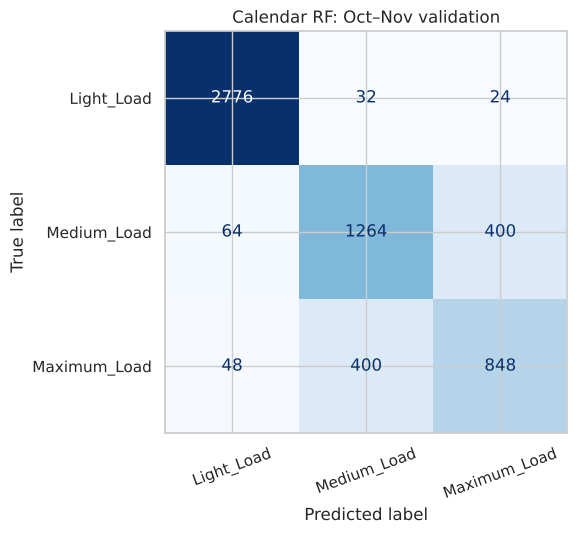

In [5]:
fig, ax = plt.subplots(figsize=(7, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y_val, baseline_predictions["Random Forest (calendar)"], labels=CLASS_LABELS),
                       display_labels=CLASS_LABELS).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Calendar RF: Oct–Nov validation")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

Light load is almost always right. The errors are Medium ↔ Maximum confusions, so the question is *when* the plant switches between those two.

## 4. Adding telemetry, with a cleaning pipeline
The audit found two kinds of corrupted sensor values:
1. **Power factors above 100%** (physically impossible).
2. **Corrupted readings with many decimals.** Genuine readings have at most 2 decimals (`3.24`, `73.21`). About 10% of values in *every* telemetry column look like `8.753692425450835`. They include every power factor above 100, and a corrupted `Usage_kWh` value is ~2× its neighbouring readings.

`SensorCleaner` sets both kinds to missing, and a median imputer fills them. The cleaner looks at one value at a time and learns nothing from the data, so it cannot leak information from validation or test.

In [6]:
corrupted = pd.DataFrame({
    "Extra-decimal values": [has_extra_decimals(train_dev[c]).sum() for c in TELEMETRY_FEATURES],
    "Missing values": [train_dev[c].isna().sum() for c in TELEMETRY_FEATURES],
}, index=TELEMETRY_FEATURES)
corrupted["Extra-decimal %"] = (corrupted["Extra-decimal values"] / len(train_dev) * 100).round(1)
display(corrupted)

usage = train_dev["Usage_kWh"]
neighbour_ratio = usage / ((usage.shift(1) + usage.shift(-1)) / 2)
print("Median Usage / mean of neighbours:")
print("  extra-decimal values:", round(neighbour_ratio[has_extra_decimals(usage)].median(), 2))
print("  normal values       :", round(neighbour_ratio[~has_extra_decimals(usage) & usage.notna()].median(), 2))

,Extra-decimal values,Missing values,Extra-decimal %
Usage_kWh,3059,1395,9.5
Lagging_Current_Reactive.Power_kVarh,2497,795,7.8
Leading_Current_Reactive_Power_kVarh,971,1057,3.0
CO2(tCO2),1288,418,4.0
Lagging_Current_Power_Factor,3157,323,9.8
Leading_Current_Power_Factor,3052,1352,9.5


Median Usage / mean of neighbours:
  extra-decimal values: 2.03
  normal values       : 0.98


In [7]:
def make_rf(cleaner):
    return Pipeline([
        ("cleaner", cleaner),
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=5,
                                              random_state=RANDOM_STATE, n_jobs=-1)),
    ])

power_factor_rf = make_rf(PowerFactorCleaner(POWER_FACTOR_COLUMNS))
sensor_rf = make_rf(SensorCleaner(TELEMETRY_FEATURES, POWER_FACTOR_COLUMNS))
combined_features = calendar_features + TELEMETRY_FEATURES

rows = [{"Model": "Calendar RF", "Accuracy": accuracy_score(y_val, baseline_predictions["Random Forest (calendar)"]),
         "Macro F1": macro_f1(y_val, baseline_predictions["Random Forest (calendar)"])}]
for name, model in [("Combined RF: power-factor cleaning", power_factor_rf),
                    ("Combined RF: full sensor cleaning", sensor_rf)]:
    pred = clone(model).fit(train[combined_features], y_train).predict(val[combined_features])
    rows.append({"Model": name, "Accuracy": accuracy_score(y_val, pred), "Macro F1": macro_f1(y_val, pred)})
pd.DataFrame(rows).round(4)

,Model,Accuracy,Macro F1
0,Calendar RF,0.8347,0.7898
1,Combined RF: power-factor cleaning,0.8366,0.7918
2,Combined RF: full sensor cleaning,0.8373,0.7925


Telemetry gives only a small gain on this split. Most of the information is in the schedule. A single validation split can hide problems, though, so the next step checks every month separately.

## 5. Chronological monthly validation
Expanding-window validation: for each month from July to November, train on all earlier months and validate on that month. This mirrors the real use case: train on the past, predict the next month.

In [8]:
validation_months = ["2018-07", "2018-08", "2018-09", "2018-10", "2018-11"]
folds = []
for month in validation_months:
    start, end = pd.Period(month).start_time, (pd.Period(month) + 1).start_time
    fold_train = train_dev[train_dev["Date_Time"] <= start]
    fold_val = train_dev[(train_dev["Date_Time"] > start) & (train_dev["Date_Time"] <= end)]
    folds.append((month, fold_train, fold_val))
    print(month, "training:", len(fold_train), "validation:", len(fold_val))

def evaluate_on_folds(model, features, name):
    rows = []
    for month, fold_train, fold_val in folds:
        pred = clone(model).fit(fold_train[features], fold_train["Load_Type"]).predict(fold_val[features])
        rows.append({"Model": name, "Month": month,
                     "Accuracy": accuracy_score(fold_val["Load_Type"], pred),
                     "Macro_F1": macro_f1(fold_val["Load_Type"], pred)})
    return rows

2018-07 training: 17376 validation: 2976
2018-08 training: 20352 validation: 2976
2018-09 training: 23328 validation: 2880
2018-10 training: 26208 validation: 2976
2018-11 training: 29184 validation: 2880


Model,Calendar RF,Combined RF
Month,,
2018-07,0.9441,0.9665
2018-08,0.8514,0.9322
2018-09,0.8802,0.9350
2018-10,1.0000,0.9886
2018-11,0.5753,0.5938


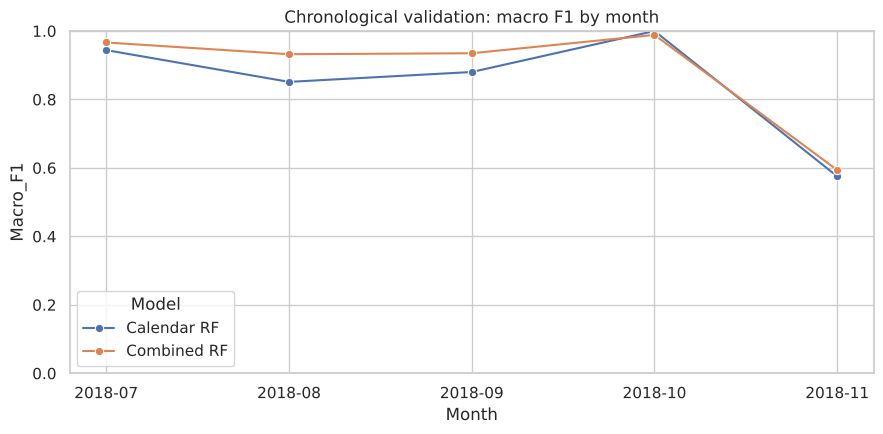

In [9]:
cv_rows = []
cv_rows += evaluate_on_folds(baselines["Random Forest (calendar)"], calendar_features, "Calendar RF")
cv_rows += evaluate_on_folds(sensor_rf, combined_features, "Combined RF")
cv_results = pd.DataFrame(cv_rows)
display(cv_results.pivot(index="Month", columns="Model", values="Macro_F1").round(4))

plt.figure(figsize=(9, 4.5))
sns.lineplot(data=cv_results, x="Month", y="Macro_F1", hue="Model", marker="o")
plt.title("Chronological validation: macro F1 by month"); plt.ylim(0, 1); plt.tight_layout(); plt.show()

Both models do well from July to October (macro F1 0.93–0.99) but **collapse in November (~0.59)**. Something changes in November that earlier months can't teach the model.

## 6. Diagnosing November: the schedule changes with the season

In [10]:
nov_train = train_dev[train_dev["Date_Time"] <= pd.Timestamp("2018-11-01")]
nov_val = train_dev[(train_dev["Date_Time"] > pd.Timestamp("2018-11-01")) & (train_dev["Date_Time"] <= TEST_START)]
nov_predictions = clone(sensor_rf).fit(nov_train[combined_features], nov_train["Load_Type"]).predict(nov_val[combined_features])
print(classification_report(nov_val["Load_Type"], nov_predictions, labels=CLASS_LABELS, zero_division=0))

              precision    recall  f1-score   support

  Light_Load       0.96      0.98      0.97      1368
 Medium_Load       0.49      0.47      0.48       864
Maximum_Load       0.33      0.33      0.33       648

    accuracy                           0.68      2880
   macro avg       0.59      0.59      0.59      2880
weighted avg       0.68      0.68      0.68      2880



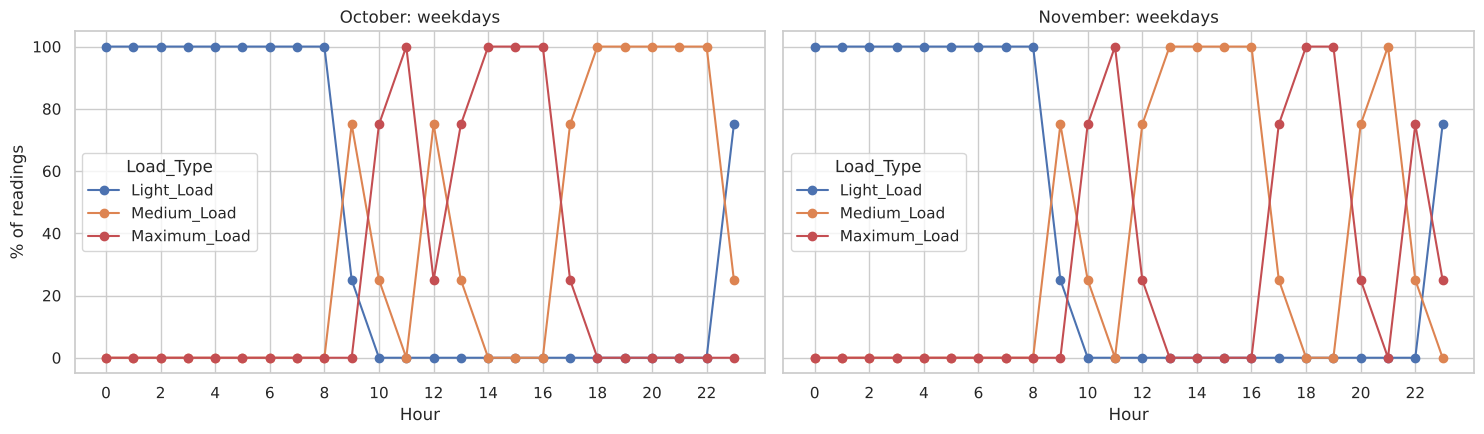

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, month, title in zip(axes, [10, 11], ["October", "November"]):
    subset = train_dev[(train_dev["Month"] == month) & (train_dev["Is_Weekend"] == 0)]
    (pd.crosstab(subset["Hour"], subset["Load_Type"], normalize="index")[CLASS_LABELS] * 100).plot(
        ax=ax, marker="o", color=["#4C72B0", "#DD8452", "#C44E52"])
    ax.set_title(f"{title}: weekdays"); ax.set_xlabel("Hour"); ax.set_ylabel("% of readings")
    ax.set_xticks(range(0, 24, 2))
plt.tight_layout(); plt.show()

In October, weekday afternoons (13–16 h) are **Maximum** and 18–22 h are **Medium**. In November it's the other way round: 13–16 h are Medium, and 17–19 h and 22 h are Maximum.
To check whether this is a one-off or a recurring pattern, the dominant schedule (most frequent load type for each weekday × 15-minute slot) is compared across all months.

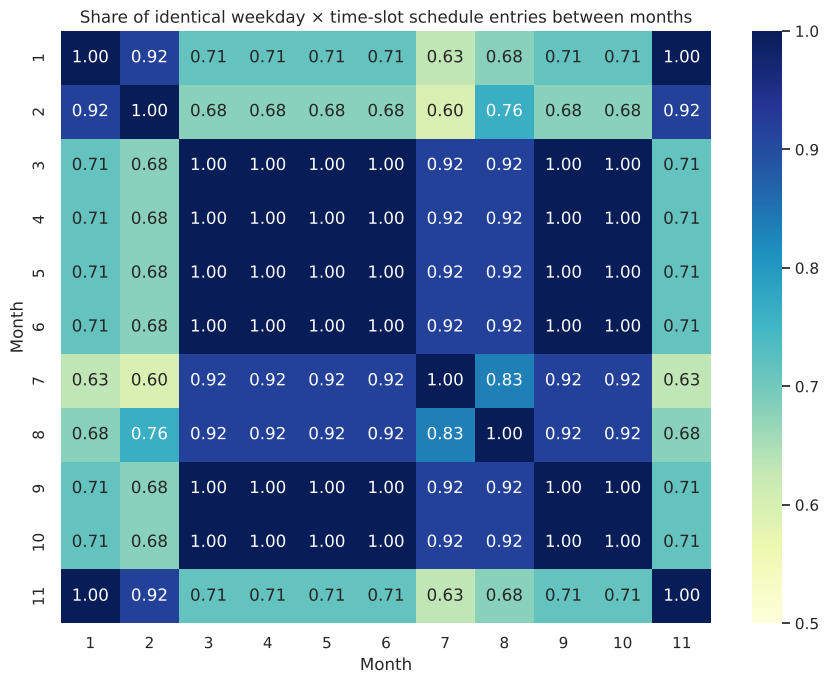

In [12]:
def dominant_schedule(data, month):
    subset = data[data["Month"] == month]
    return subset.groupby(["Day_of_Week", "Time_Slot"])["Load_Type"].agg(lambda s: s.mode().iloc[0])

monthly_schedules = {m: dominant_schedule(train_dev, m) for m in range(1, 12)}
similarity = pd.DataFrame(index=range(1, 12), columns=range(1, 12), dtype=float)
for m1 in range(1, 12):
    for m2 in range(1, 12):
        both = pd.concat([monthly_schedules[m1], monthly_schedules[m2]], axis=1, join="inner")
        similarity.loc[m1, m2] = (both.iloc[:, 0] == both.iloc[:, 1]).mean()

plt.figure(figsize=(9, 7))
sns.heatmap(similarity, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0.5, vmax=1)
plt.title("Share of identical weekday × time-slot schedule entries between months")
plt.xlabel("Month"); plt.ylabel("Month"); plt.tight_layout(); plt.show()

In [13]:
# Can January's schedule predict November?
jan_lookup = monthly_schedules[1]
jan_on_nov = jan_lookup.reindex(pd.MultiIndex.from_frame(nov_val[["Day_of_Week", "Time_Slot"]])).to_numpy()
pd.DataFrame([
    {"Approach": "Combined RF trained on Jan–Oct", "Accuracy": accuracy_score(nov_val["Load_Type"], nov_predictions),
     "Macro F1": macro_f1(nov_val["Load_Type"], nov_predictions)},
    {"Approach": "January's schedule copied to November", "Accuracy": accuracy_score(nov_val["Load_Type"], jan_on_nov),
     "Macro F1": macro_f1(nov_val["Load_Type"], jan_on_nov)},
]).round(4)

,Approach,Accuracy,Macro F1
0,Combined RF trained on Jan–Oct,0.6812,0.5938
1,January's schedule copied to November,0.9417,0.9422


**Finding:** the months form two schedule regimes.
* **Winter: January, February, November.** These months share ~92–100% of their schedule. December is assumed to belong here too, as it's the same season. That assumption is tested in §8.
* **March–October.** These share ~92–100% of their schedule with each other but only ~60–76% with the winter months.

Simply copying January's schedule onto November gives 0.94 macro F1, compared with 0.59 for the random forest. The random forest fails because it gives most weight to the most recent months (March–October) and has no feature telling it that November follows the winter schedule.

This looks like a seasonal time-of-use electricity tariff, where peak hours differ between winter and the rest of the year. It becomes a feature:
`Schedule_Regime = 0` for November–February, `1` for March–October (`add_calendar_features` in `src/preprocessing.py`).

## 7. Using the schedule regime and choosing the final model
Candidates, all evaluated on the same monthly folds:
* **Regime lookup:** the most frequent load type per (regime, weekday, time slot). A transparent, rule-like baseline learned from the data.
* **RF + regime:** the combined random forest with `Schedule_Regime` added.
* **RF + regime, without `Month`:** `Month` causes a problem. A fold's validation month, and December in the final test, is never present in its training data. The tree then treats the unseen value like the nearest month it has seen, which can be the wrong season. `Schedule_Regime` carries the seasonal information in a form that generalises.

In [14]:
regime_features = ["Schedule_Regime", "Day_of_Week", "Time_Slot"]
features_regime = combined_features + ["Schedule_Regime"]
features_regime_no_month = [f for f in features_regime if f != "Month"]

candidates = {
    "Combined RF": (sensor_rf, combined_features),
    "Regime lookup": (RegimeScheduleLookup(), regime_features),
    "RF + regime": (sensor_rf, features_regime),
    "RF + regime, no Month": (sensor_rf, features_regime_no_month),
}
cv_rows = []
for name, (model, features) in candidates.items():
    cv_rows += evaluate_on_folds(model, features, name)
cv_results = pd.DataFrame(cv_rows)

display(cv_results.pivot(index="Month", columns="Model", values="Macro_F1")[list(candidates)].round(4))
cv_summary = (cv_results.groupby("Model")
              .agg(Mean_Accuracy=("Accuracy", "mean"), Mean_Macro_F1=("Macro_F1", "mean"),
                   Std_Macro_F1=("Macro_F1", "std"), Worst_Month_F1=("Macro_F1", "min"))
              .sort_values("Mean_Macro_F1", ascending=False))
cv_summary.round(4)

Model,Combined RF,Regime lookup,RF + regime,"RF + regime, no Month"
Month,,,,
2018-07,0.9665,0.9441,0.9690,0.9650
2018-08,0.9322,0.8845,0.9314,0.9339
2018-09,0.9350,0.8802,0.9381,0.9386
2018-10,0.9886,1.0000,0.9886,0.9915
2018-11,0.5938,0.9422,0.6120,0.9179


,Mean_Accuracy,Mean_Macro_F1,Std_Macro_F1,Worst_Month_F1
Model,,,,
"RF + regime, no Month",0.9499,0.9494,0.0290,0.9179
Regime lookup,0.9311,0.9302,0.0495,0.8802
RF + regime,0.9049,0.8878,0.1559,0.6120
Combined RF,0.9001,0.8832,0.1635,0.5938


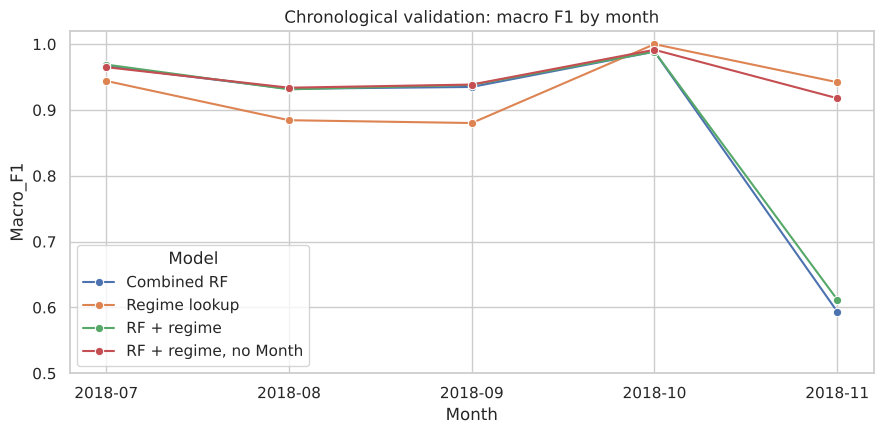

In [15]:
plt.figure(figsize=(9, 4.5))
sns.lineplot(data=cv_results, x="Month", y="Macro_F1", hue="Model", marker="o")
plt.title("Chronological validation: macro F1 by month"); plt.ylim(0.5, 1.02); plt.tight_layout(); plt.show()

In [16]:
FINAL_MODEL_NAME = cv_summary.index[0]          # chosen on Jul–Nov validation only
final_pipeline, final_features = candidates[FINAL_MODEL_NAME]
print("Selected model:", FINAL_MODEL_NAME)
print("Features:", final_features)

Selected model: RF + regime, no Month
Features: ['Hour', 'Day_of_Week', 'Time_Slot', 'Is_Weekend', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'Schedule_Regime']


* Adding `Schedule_Regime` while **keeping** `Month` barely helps November. The tree still uses `Month` = 11, a value it has never seen, and keeps applying the March–October schedule.
* **Removing `Month`** fixes November (0.59 → ~0.92) without hurting the other months. This model has the best mean and the best worst-month score, so it is selected.
* The regime lookup is strong and fully interpretable, but it can only repeat the most frequent label per slot. The random forest can also use the telemetry, which helps in the slots where the label isn't fixed by the schedule. It scores higher in 3 of the 5 months and on average, and its worst month is better.

## 8. Final evaluation on December 2018
The selected pipeline is refit on all of January–November and evaluated **once** on December.
For reference, the original Combined RF (with `Month`, without the regime) is evaluated on December as well.

In [17]:
final_model = clone(final_pipeline).fit(train_dev[final_features], train_dev["Load_Type"])
test_predictions = final_model.predict(test[final_features])
y_test = test["Load_Type"]

original_model = clone(power_factor_rf).fit(train_dev[combined_features], train_dev["Load_Type"])
original_predictions = original_model.predict(test[combined_features])

def summarise(name, pred):
    return {"Model": name, "Accuracy": accuracy_score(y_test, pred),
            "Macro Precision": precision_score(y_test, pred, average="macro", zero_division=0),
            "Macro Recall": recall_score(y_test, pred, average="macro", zero_division=0),
            "Macro F1": macro_f1(y_test, pred)}

final_metrics_table = pd.DataFrame([
    summarise(f"Final: {FINAL_MODEL_NAME}", test_predictions),
    summarise("Original Combined RF", original_predictions),
]).set_index("Model").round(4)
final_metrics_table

,Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,
"Final: RF + regime, no Month",0.9553,0.9524,0.9444,0.9482
Original Combined RF,0.8945,0.8732,0.8715,0.8646


In [18]:
print(classification_report(y_test, test_predictions, labels=CLASS_LABELS, digits=3, zero_division=0))

              precision    recall  f1-score   support

  Light_Load      0.960     0.969     0.965      1744
 Medium_Load      0.947     0.959     0.953       704
Maximum_Load      0.950     0.905     0.927       528

    accuracy                          0.955      2976
   macro avg      0.952     0.944     0.948      2976
weighted avg      0.955     0.955     0.955      2976



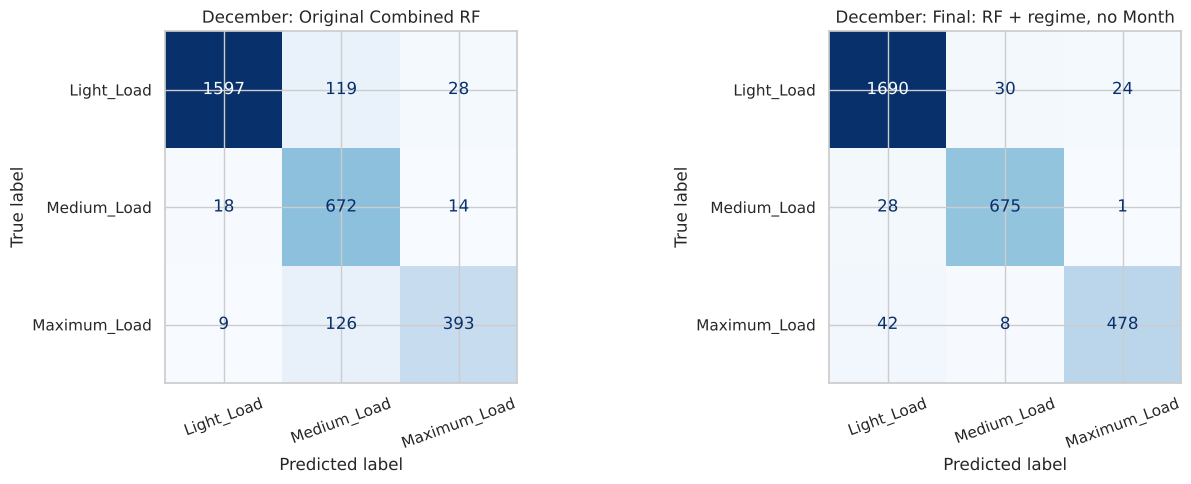

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, pred, title in [(axes[0], original_predictions, "Original Combined RF"),
                        (axes[1], test_predictions, f"Final: {FINAL_MODEL_NAME}")]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=CLASS_LABELS), display_labels=CLASS_LABELS).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"December: {title}")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

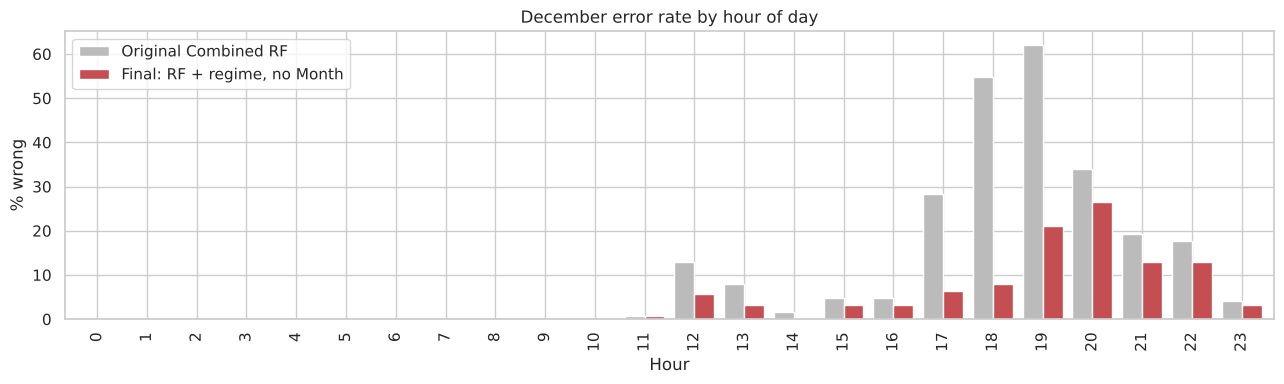

In [20]:
hourly_errors = pd.DataFrame({
    "Original Combined RF": (original_predictions != y_test.to_numpy()),
    f"Final: {FINAL_MODEL_NAME}": (test_predictions != y_test.to_numpy()),
}).groupby(test["Hour"].to_numpy()).mean() * 100
hourly_errors.plot.bar(figsize=(13, 4), color=["#BBBBBB", "#C44E52"], width=0.8)
plt.title("December error rate by hour of day"); plt.xlabel("Hour"); plt.ylabel("% wrong")
plt.tight_layout(); plt.show()

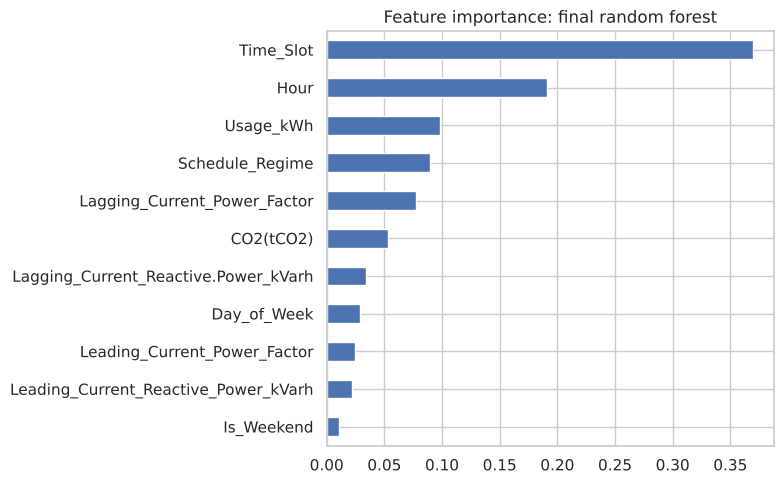

In [21]:
importance = pd.Series(final_model.named_steps["classifier"].feature_importances_, index=final_features)
importance.sort_values().plot.barh(figsize=(8, 5), color="#4C72B0")
plt.title("Feature importance: final random forest"); plt.tight_layout(); plt.show()

## 9. Saving the model, metrics and predictions
The custom transformer lives in `src/preprocessing.py`, so the saved pipeline can be loaded outside this notebook.

In [22]:
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

model_path = MODELS_DIR / "final_random_forest.joblib"
joblib.dump(final_model, model_path)

final_row = final_metrics_table.iloc[0]
metrics_to_save = {
    "model": FINAL_MODEL_NAME,
    "test_period": "December 2018",
    "test_samples": int(len(y_test)),
    "accuracy": float(final_row["Accuracy"]),
    "macro_precision": float(final_row["Macro Precision"]),
    "macro_recall": float(final_row["Macro Recall"]),
    "macro_f1": float(final_row["Macro F1"]),
}
(RESULTS_DIR / "final_metrics.json").write_text(json.dumps(metrics_to_save, indent=4))

predictions_df = pd.DataFrame({"Date_Time": test["Date_Time"].to_numpy(),
                               "Actual_Load_Type": y_test.to_numpy(),
                               "Predicted_Load_Type": test_predictions})
predictions_df["Correct"] = predictions_df["Actual_Load_Type"] == predictions_df["Predicted_Load_Type"]
predictions_df.to_csv(RESULTS_DIR / "final_predictions.csv", index=False)

metadata = {
    "model_name": FINAL_MODEL_NAME,
    "target": "Load_Type",
    "features": list(final_features),
    "classes": final_model.classes_.tolist(),
    "preprocessing": "src/preprocessing.py: load_clean_timeline, add_calendar_features, SensorCleaner",
    "training_period": "January–November 2018",
    "test_period": "December 2018",
}
(MODELS_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=4, ensure_ascii=False))
print(json.dumps(metrics_to_save, indent=2))

{
  "model": "RF + regime, no Month",
  "test_period": "December 2018",
  "test_samples": 2976,
  "accuracy": 0.9553,
  "macro_precision": 0.9524,
  "macro_recall": 0.9444,
  "macro_f1": 0.9482
}


In [23]:
# reload check: the saved pipeline gives identical predictions
reloaded = joblib.load(model_path)
assert np.array_equal(reloaded.predict(test[final_features]), test_predictions)
print("Reloaded model reproduces all", len(test_predictions), "December predictions.")

Reloaded model reproduces all 2976 December predictions.


## 10. Conclusions

* **Load type follows a fixed weekly schedule** (weekday × 15-minute slot) that **changes with the season**. November–February use a different afternoon and evening pattern from March–October. This was found by investigating why chronological validation failed in November.
* Modelling the season as `Schedule_Regime` and **removing `Month`** (whose unseen values cannot generalise) raised the worst validation month from ~0.59 to ~0.92 macro F1. The final model was selected on Jul–Nov validation only.
* **December 2018 (held-out test):** see the table in §8. Accuracy is **0.955** and macro F1 **0.948**, against 0.895 / 0.865 for the original Combined RF. The biggest gains are at 17–19 h, where the winter schedule differs.
* **Data quality:** midnight timestamps were re-dated, a duplicate timestamp was removed, and corrupted readings (power factor > 100%, and values with extra decimals in every sensor column) were set to missing and imputed inside the pipeline.

**Limitations and next steps**
* The regime split (Nov–Feb vs Mar–Oct) is inferred from one year of data. With more years it could be learned automatically, for example by clustering monthly schedules.
* The remaining December errors are concentrated in 19–22 h, around the switching points of the winter evening schedule. Training data for that schedule comes from only three months (Jan, Feb, Nov), so more winter data would help most.
* A gradient-boosting model and lag features of recent usage could add a few more points.